In [1]:
from pathlib import Path
import sys

# Thêm thư mục gốc vào sys.path để notebook trong notebooks/ có thể import features.py
project_root = Path("..").resolve()
if str(project_root) not in sys.path:
  sys.path.append(str(project_root))

from features import (
    build_severity_weight_dictionary,
    clean_raw_symptom_dataset,
    create_symptom_feature_matrices,
    generate_exploratory_summary,
    load_all_raw_datasets,
    split_and_save_processed_data,
)

raw_directory_path = project_root / "data" / "raw"
processed_directory_path = project_root / "data" / "processed"
reports_directory_path = project_root / "reports"

# 1. Đọc 4 tệp dữ liệu gốc
(
    dataframe_raw_dataset,
    dataframe_raw_severity,
    dataframe_raw_description,
    dataframe_raw_precaution,
) = load_all_raw_datasets(raw_directory_path)

# 2. Thống kê EDA
exploratory_summary_dictionary = generate_exploratory_summary(
    dataframe_raw_dataset, dataframe_raw_severity
)
print("Thống kê EDA:", exploratory_summary_dictionary)

# 3. Làm sạch dữ liệu & tạo từ điển trọng số
dataframe_unique_records = clean_raw_symptom_dataset(dataframe_raw_dataset)
severity_weight_dictionary = build_severity_weight_dictionary(
    dataframe_raw_severity
)

# 4. Xoay ngang thành ma trận đặc trưng
matrix_binary_symptoms, matrix_weighted_symptoms = (
    create_symptom_feature_matrices(
        dataframe_unique_records, severity_weight_dictionary
    )
)

# 5. Mã hóa nhãn, chia Train/Test và lưu file đầu ra
processed_outputs = split_and_save_processed_data(
    matrix_binary_symptoms=matrix_binary_symptoms,
    matrix_weighted_symptoms=matrix_weighted_symptoms,
    series_disease_names=dataframe_unique_records["Disease"],
    processed_directory_path=processed_directory_path,
    reports_directory_path=reports_directory_path,
    exploratory_summary_dictionary=exploratory_summary_dictionary,
)

print(
    "Hoàn tất! Kích thước X_train:",
    processed_outputs["features_train_binary"].shape,
)
print(
    "Hoàn tất! Kích thước X_test:",
    processed_outputs["features_test_binary"].shape,
)

Thống kê EDA: {'total_raw_rows': 4920, 'total_raw_columns': 18, 'total_unique_diseases': 41, 'total_duplicate_rows': 4616, 'total_unique_records': 304, 'min_symptoms_per_patient': 3, 'max_symptoms_per_patient': 17, 'average_symptoms_per_patient': 7.45, 'raw_symptom_string_count': 131, 'stripped_symptom_string_count': 131, 'unmatched_symptoms_with_severity': ['dischromic _patches', 'foul_smell_of urine', 'spotting_ urination']}
Hoàn tất! Kích thước X_train: (243, 131)
Hoàn tất! Kích thước X_test: (61, 131)


=== [PHÂN TÍCH SÂU 1] KIỂM TRA TRÙNG LẶP TỔ HỢP TRIỆU CHỨNG ===
Số tổ hợp triệu chứng giống hệt nhau nhưng thuộc nhiều bệnh khác nhau: 0

=== [PHÂN TÍCH SÂU 2] TOP 5 BỆNH CÓ TỔNG ĐIỂM NGHIÊM TRỌNG CAO NHẤT ===
                unique_record_count  average_symptom_count  \
Disease                                                      
Common Cold                       9                  16.11   
Tuberculosis                      9                  15.11   
Hepatitis E                       9                  12.11   
Dengue                           10                  13.10   
Hypothyroidism                    8                  12.12   

                average_severity_score  
Disease                                 
Common Cold                      72.89  
Tuberculosis                     71.33  
Hepatitis E                      57.89  
Dengue                           51.40  
Hypothyroidism                   49.75  

=== [PHÂN TÍCH SÂU 3] TOP 5 BỆNH CÓ TỔNG ĐIỂM NGHIÊM TRỌNG THẤP NHẤ

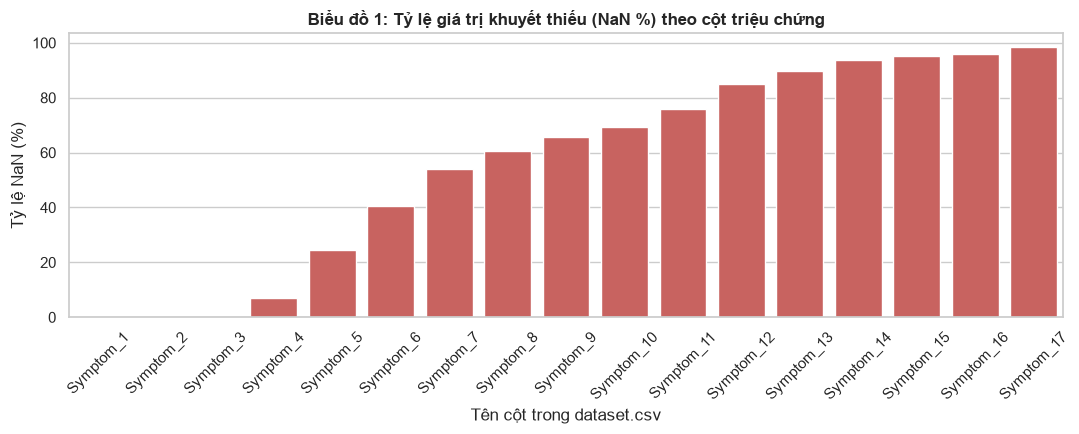

C:\Users\ASUS\AppData\Local\Temp\ipykernel_4476\3611238893.py:149: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


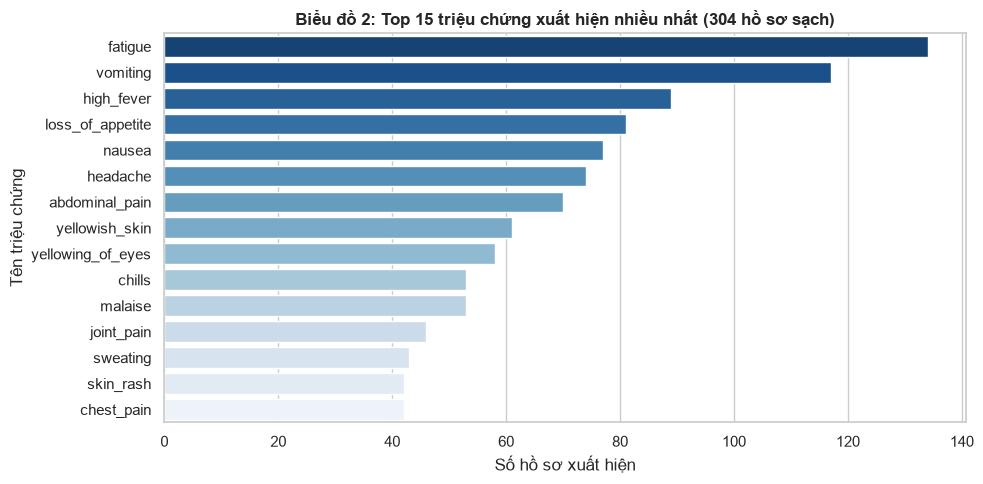

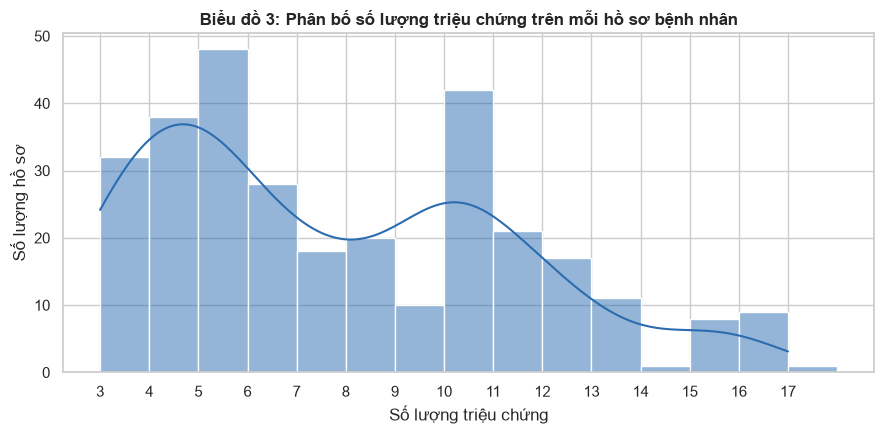

C:\Users\ASUS\AppData\Local\Temp\ipykernel_4476\3611238893.py:181: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


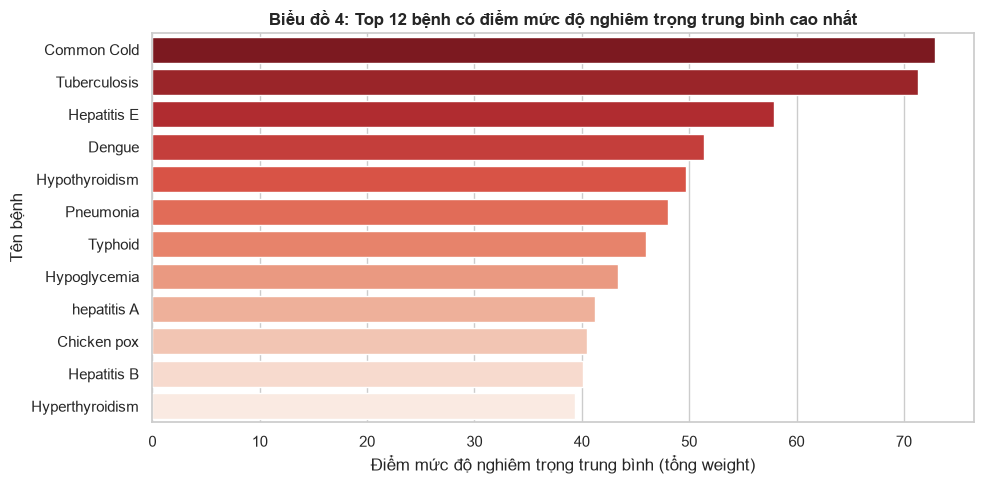


Đã xuất xong 4 biểu đồ vào reports/figures/ và bảng thống kê vào reports/thong_ke_theo_tung_benh.csv!


In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Cấu hình giao diện biểu đồ rõ nét để đưa vào báo cáo
sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"

# Xác định đường dẫn thư mục dự án
project_root = (
    Path("..").resolve() if Path("../data/processed").exists() else Path(".").resolve()
)
raw_directory_path = project_root / "data" / "raw"
processed_directory_path = project_root / "data" / "processed"
figures_directory_path = project_root / "reports" / "figures"
figures_directory_path.mkdir(parents=True, exist_ok=True)

# 1. Đọc dữ liệu thô (để vẽ biểu đồ tỷ lệ NaN) và dữ liệu sạch từ data/processed/
dataframe_raw_dataset = pd.read_csv(raw_directory_path / "dataset.csv")
matrix_binary_symptoms = pd.read_csv(
    processed_directory_path / "matrix_binary_symptoms.csv"
)
matrix_weighted_symptoms = pd.read_csv(
    processed_directory_path / "matrix_weighted_symptoms.csv"
)
disease_class_names = np.load(
    processed_directory_path / "disease_class_names.npy", allow_pickle=True
)

# Khôi phục cột tên bệnh tương ứng cho 304 dòng sạch
symptom_column_names = [f"Symptom_{index}" for index in range(1, 18)]
disease_typo_dictionary = {
    "Dimorphic hemmorhoids(piles)": "Dimorphic hemorrhoids(piles)"
}
symptom_typo_dictionary = {
    "dischromic _patches": "dischromic_patches",
    "spotting_ urination": "spotting_urination",
    "foul_smell_of urine": "foul_smell_ofurine",
}

dataframe_cleaned_text = dataframe_raw_dataset.copy()
dataframe_cleaned_text["Disease"] = (
    dataframe_cleaned_text["Disease"]
    .str.strip()
    .replace(disease_typo_dictionary)
)
for column_name in symptom_column_names:
  dataframe_cleaned_text[column_name] = dataframe_cleaned_text[
      column_name
  ].apply(
      lambda cell_value: (
          symptom_typo_dictionary.get(cell_value.strip(), cell_value.strip())
          if pd.notna(cell_value)
          else np.nan
      )
  )
dataframe_unique_records = dataframe_cleaned_text.drop_duplicates().reset_index(
    drop=True
)

# ------------------------------------------------------------------------------
# PHÂN TÍCH 1: KIỂM TRA TỔ HỢP TRIỆU CHỨNG TRÙNG NHAU GIỮA CÁC BỆNH KHÁC NHAU
# ------------------------------------------------------------------------------
row_symptom_signatures = matrix_binary_symptoms.apply(
    lambda row_series: tuple(row_series.values), axis=1
)
dataframe_signatures = pd.DataFrame({
    "Disease": dataframe_unique_records["Disease"],
    "symptom_signature": row_symptom_signatures,
})
diseases_per_signature = dataframe_signatures.groupby("symptom_signature")[
    "Disease"
].unique()
overlapping_disease_pairs = diseases_per_signature[
    diseases_per_signature.apply(len) > 1
]

print("=== [PHÂN TÍCH SÂU 1] KIỂM TRA TRÙNG LẶP TỔ HỢP TRIỆU CHỨNG ===")
print(
    "Số tổ hợp triệu chứng giống hệt nhau nhưng thuộc nhiều bệnh khác nhau:",
    len(overlapping_disease_pairs),
)

# ------------------------------------------------------------------------------
# PHÂN TÍCH 2: THỐNG KÊ SỐ TRIỆU CHỨNG & ĐIỂM NGHIÊM TRỌNG THEO TỪNG BỆNH
# ------------------------------------------------------------------------------
dataframe_disease_metrics = pd.DataFrame({
    "Disease": dataframe_unique_records["Disease"],
    "symptom_count": matrix_binary_symptoms.sum(axis=1),
    "total_severity_score": matrix_weighted_symptoms.sum(axis=1),
})

summary_by_disease = (
    dataframe_disease_metrics.groupby("Disease")
    .agg(
        unique_record_count=("symptom_count", "count"),
        average_symptom_count=("symptom_count", "mean"),
        average_severity_score=("total_severity_score", "mean"),
    )
    .sort_values(by="average_severity_score", ascending=False)
)

print("\n=== [PHÂN TÍCH SÂU 2] TOP 5 BỆNH CÓ TỔNG ĐIỂM NGHIÊM TRỌNG CAO NHẤT ===")
print(summary_by_disease.head(5).round(2))

print("\n=== [PHÂN TÍCH SÂU 3] TOP 5 BỆNH CÓ TỔNG ĐIỂM NGHIÊM TRỌNG THẤP NHẤT ===")
print(summary_by_disease.tail(5).round(2))

# Lưu bảng thống kê theo từng bệnh ra thư mục reports/
summary_by_disease.round(2).to_csv(
    project_root / "reports" / "thong_ke_theo_tung_benh.csv"
)

# ------------------------------------------------------------------------------
# XUẤT BỘ 4 BIỂU ĐỒ EDA VÀO THƯ MỤC reports/figures/
# ------------------------------------------------------------------------------

# Biểu đồ 1: Tỷ lệ giá trị NaN (%) từ Symptom_1 đến Symptom_17 trên dữ liệu gốc
nan_percentage_series = (
    dataframe_raw_dataset[symptom_column_names].isnull().sum()
    / len(dataframe_raw_dataset)
    * 100
).round(2)

plt.figure(figsize=(11, 4.5))
sns.barplot(
    x=nan_percentage_series.index,
    y=nan_percentage_series.values,
    color="#d9534f",
)
plt.title("Biểu đồ 1: Tỷ lệ giá trị khuyết thiếu (NaN %) theo cột triệu chứng")
plt.xlabel("Tên cột trong dataset.csv")
plt.ylabel("Tỷ lệ NaN (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(figures_directory_path / "01_ty_le_nan_theo_cot.png", dpi=150)
plt.show()

# Biểu đồ 2: Top 15 triệu chứng phổ biến nhất trên 304 hồ sơ sạch
symptom_frequency_clean = (
    matrix_binary_symptoms.sum(axis=0).sort_values(ascending=False).head(15)
)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=symptom_frequency_clean.values,
    y=symptom_frequency_clean.index,
    palette="Blues_r",
)
plt.title("Biểu đồ 2: Top 15 triệu chứng xuất hiện nhiều nhất (304 hồ sơ sạch)")
plt.xlabel("Số hồ sơ xuất hiện")
plt.ylabel("Tên triệu chứng")
plt.tight_layout()
plt.savefig(figures_directory_path / "02_top_15_trieu_chung.png", dpi=150)
plt.show()

# Biểu đồ 3: Phân bố số lượng triệu chứng trên mỗi hồ sơ bệnh nhân (304 hồ sơ)
plt.figure(figsize=(9, 4.5))
sns.histplot(
    dataframe_disease_metrics["symptom_count"],
    bins=range(3, 19),
    kde=True,
    color="#2b6cb0",
)
plt.title("Biểu đồ 3: Phân bố số lượng triệu chứng trên mỗi hồ sơ bệnh nhân")
plt.xlabel("Số lượng triệu chứng")
plt.ylabel("Số lượng hồ sơ")
plt.xticks(range(3, 18))
plt.tight_layout()
plt.savefig(figures_directory_path / "03_phan_bo_so_trieu_chung.png", dpi=150)
plt.show()

# Biểu đồ 4: Top 12 bệnh có tổng điểm mức độ nghiêm trọng trung bình cao nhất
top_12_severe_diseases = summary_by_disease.head(12)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=top_12_severe_diseases["average_severity_score"],
    y=top_12_severe_diseases.index,
    palette="Reds_r",
)
plt.title("Biểu đồ 4: Top 12 bệnh có điểm mức độ nghiêm trọng trung bình cao nhất")
plt.xlabel("Điểm mức độ nghiêm trọng trung bình (tổng weight)")
plt.ylabel("Tên bệnh")
plt.tight_layout()
plt.savefig(
    figures_directory_path / "04_top_12_benh_nghiem_trong.png", dpi=150
)
plt.show()

print(
    "\nĐã xuất xong 4 biểu đồ vào reports/figures/ và bảng thống kê vào"
    " reports/thong_ke_theo_tung_benh.csv!"
)

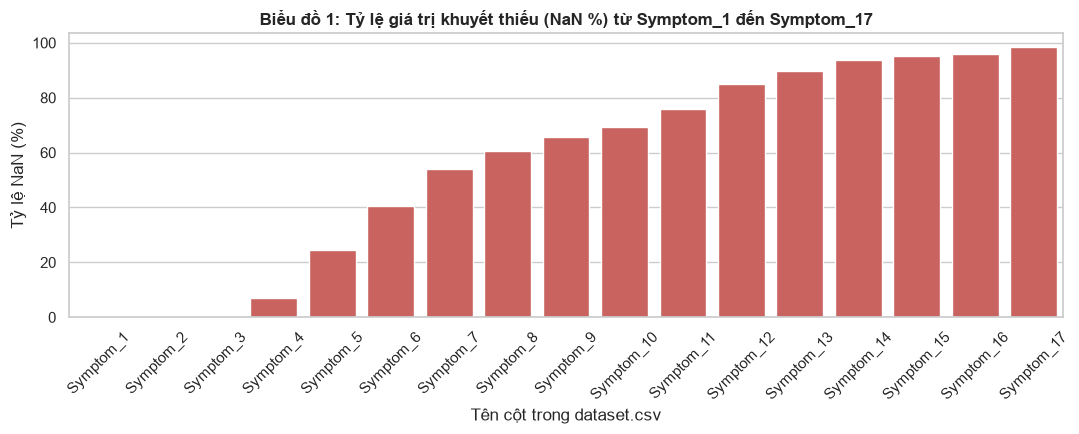

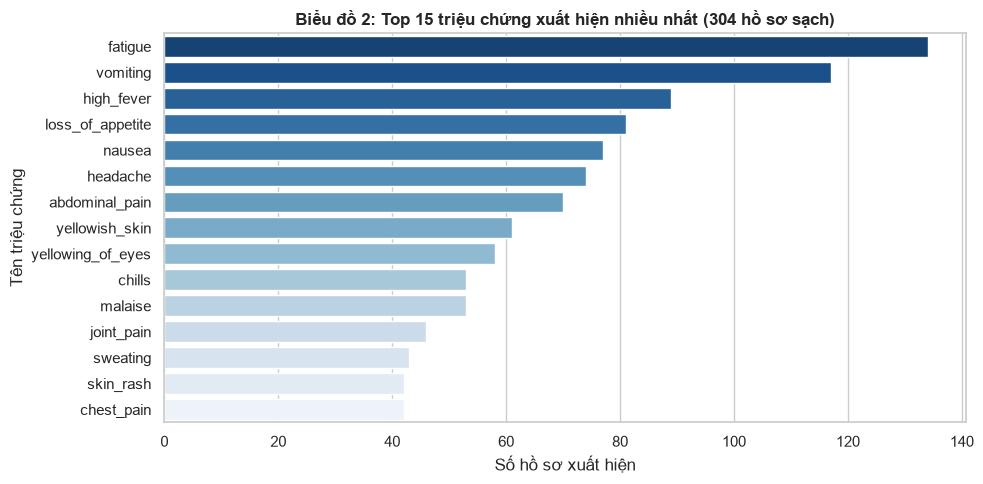

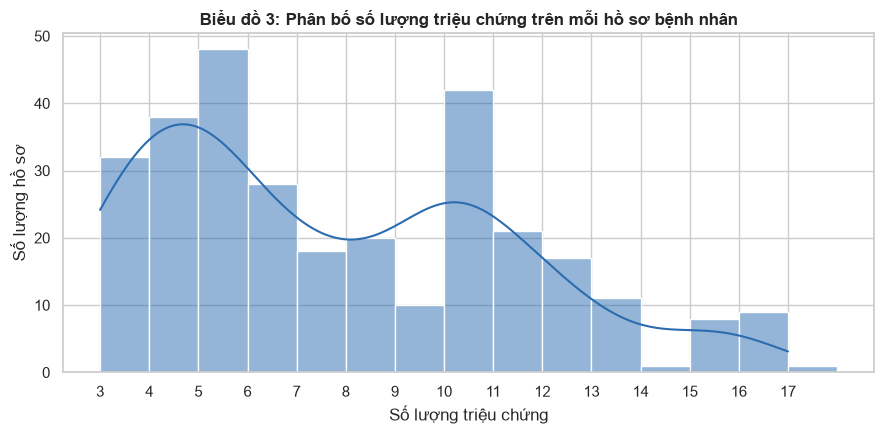

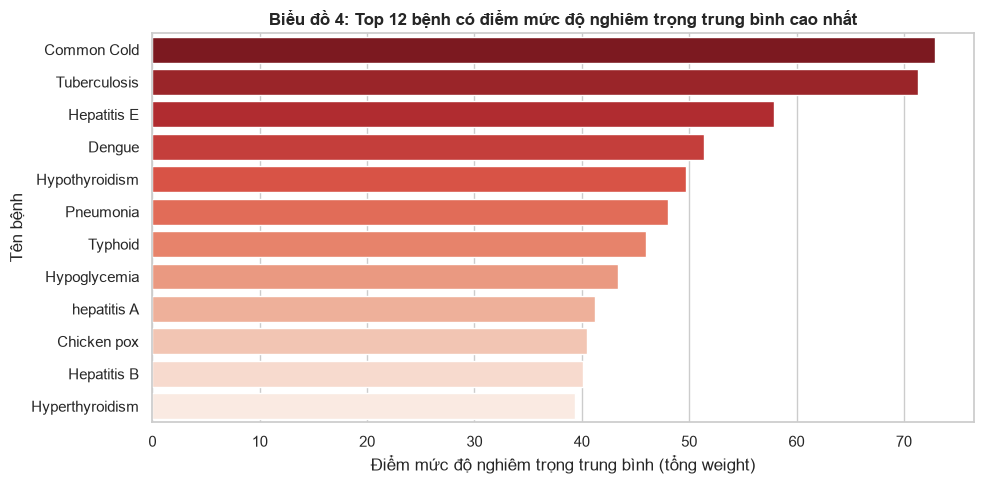

Hoàn tất! Đã lưu 4 biểu đồ vào thư mục: D:\Nhom1_26CNTT_PhanDoanBenh\03_SourceCode\reports\figures
Đã lưu bảng thống kê 41 bệnh vào: D:\Nhom1_26CNTT_PhanDoanBenh\03_SourceCode\reports\thong_ke_theo_tung_benh.csv


In [3]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ==============================================================================
# BƯỚC 1: CẤU HÌNH GIAO DIỆN BIỂU ĐỒ & ĐƯỜNG DẪN THƯ MỤC
# ==============================================================================

# Thiết lập nền lưới trắng và kích thước mặc định rõ nét cho toàn bộ biểu đồ
sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"

# Tự động nhận diện thư mục gốc của dự án (03_SourceCode)
project_root_directory = (
    Path("..").resolve()
    if Path("../data/processed").exists()
    else Path(".").resolve()
)
raw_directory_path = project_root_directory / "data" / "raw"
processed_directory_path = project_root_directory / "data" / "processed"
reports_directory_path = project_root_directory / "reports"
figures_directory_path = reports_directory_path / "figures"

# Tạo thư mục reports/figures/ nếu chưa có để lưu ảnh biểu đồ .png
figures_directory_path.mkdir(parents=True, exist_ok=True)


# ==============================================================================
# BƯỚC 2: ĐỌC DỮ LIỆU GỐC & DỮ LIỆU SẠCH TỪ DATA/PROCESSED/
# ==============================================================================

# Đọc bảng dữ liệu thô để vẽ biểu đồ tỷ lệ khuyết thiếu (NaN) ban đầu
dataframe_raw_dataset = pd.read_csv(raw_directory_path / "dataset.csv")

# Đọc 2 ma trận đặc trưng sạch (304 x 131) đã xuất ở bước tiền xử lý
matrix_binary_symptoms = pd.read_csv(
    processed_directory_path / "matrix_binary_symptoms.csv"
)
matrix_weighted_symptoms = pd.read_csv(
    processed_directory_path / "matrix_weighted_symptoms.csv"
)

# Khôi phục cột tên bệnh sạch tương ứng với 304 hồ sơ độc nhất để nhóm theo từng bệnh
symptom_column_names = [f"Symptom_{index}" for index in range(1, 18)]
disease_typo_dictionary = {
    "Dimorphic hemmorhoids(piles)": "Dimorphic hemorrhoids(piles)"
}
symptom_typo_dictionary = {
    "dischromic _patches": "dischromic_patches",
    "spotting_ urination": "spotting_urination",
    "foul_smell_of urine": "foul_smell_ofurine",
}

dataframe_cleaned_text = dataframe_raw_dataset.copy()
dataframe_cleaned_text["Disease"] = (
    dataframe_cleaned_text["Disease"]
    .str.strip()
    .replace(disease_typo_dictionary)
)
for column_name in symptom_column_names:
  dataframe_cleaned_text[column_name] = dataframe_cleaned_text[
      column_name
  ].apply(
      lambda cell_value: (
          symptom_typo_dictionary.get(cell_value.strip(), cell_value.strip())
          if pd.notna(cell_value)
          else np.nan
      )
  )
dataframe_unique_records = dataframe_cleaned_text.drop_duplicates().reset_index(
    drop=True
)


# ==============================================================================
# BƯỚC 3: TÍNH TOÁN CHỈ SỐ TỔNG HỢP THEO TỪNG BỆNH & KIỂM TRA TRÙNG TỔ HỢP
# ==============================================================================

# Tạo bảng tổng hợp số triệu chứng và tổng điểm nghiêm trọng trên từng hồ sơ (304 dòng)
dataframe_patient_metrics = pd.DataFrame({
    "Disease": dataframe_unique_records["Disease"],
    "symptom_count": matrix_binary_symptoms.sum(axis=1),
    "total_severity_score": matrix_weighted_symptoms.sum(axis=1),
})

# Gom nhóm theo 41 loại bệnh để tính trung bình số triệu chứng và điểm mức độ nặng
dataframe_disease_summary = (
    dataframe_patient_metrics.groupby("Disease")
    .agg(
        unique_record_count=("symptom_count", "count"),
        average_symptom_count=("symptom_count", "mean"),
        average_severity_score=("total_severity_score", "mean"),
    )
    .sort_values(by="average_severity_score", ascending=False)
)

# Xuất bảng thống kê chi tiết 41 bệnh ra thư mục reports/
dataframe_disease_summary.round(2).to_csv(
    reports_directory_path / "thong_ke_theo_tung_benh.csv"
)


# ==============================================================================
# BƯỚC 4: VẼ VÀ LƯU 4 BIỂU ĐỒ EDA VÀO REPORTS/FIGURES/
# ==============================================================================

# --- Biểu đồ 1: Tỷ lệ khuyết thiếu (NaN %) theo từng cột Symptom_1 -> Symptom_17 ---
nan_percentage_by_column = (
    dataframe_raw_dataset[symptom_column_names].isnull().sum()
    / len(dataframe_raw_dataset)
    * 100
).round(2)

plt.figure(figsize=(11, 4.5))
sns.barplot(
    x=nan_percentage_by_column.index,
    y=nan_percentage_by_column.values,
    color="#d9534f",
)
plt.title(
    "Biểu đồ 1: Tỷ lệ giá trị khuyết thiếu (NaN %) từ Symptom_1 đến Symptom_17"
)
plt.xlabel("Tên cột trong dataset.csv")
plt.ylabel("Tỷ lệ NaN (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(figures_directory_path / "01_ty_le_nan_theo_cot.png", dpi=150)
plt.show()

# --- Biểu đồ 2: Top 15 triệu chứng phổ biến nhất trên 304 hồ sơ sạch ---
top_15_symptom_frequencies = (
    matrix_binary_symptoms.sum(axis=0).sort_values(ascending=False).head(15)
)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=top_15_symptom_frequencies.values,
    y=top_15_symptom_frequencies.index,
    hue=top_15_symptom_frequencies.index,
    palette="Blues_r",
    legend=False,
)
plt.title("Biểu đồ 2: Top 15 triệu chứng xuất hiện nhiều nhất (304 hồ sơ sạch)")
plt.xlabel("Số hồ sơ xuất hiện")
plt.ylabel("Tên triệu chứng")
plt.tight_layout()
plt.savefig(figures_directory_path / "02_top_15_trieu_chung.png", dpi=150)
plt.show()

# --- Biểu đồ 3: Phân bố số lượng triệu chứng trên mỗi hồ sơ bệnh nhân ---
plt.figure(figsize=(9, 4.5))
sns.histplot(
    dataframe_patient_metrics["symptom_count"],
    bins=range(3, 19),
    kde=True,
    color="#2b6cb0",
)
plt.title("Biểu đồ 3: Phân bố số lượng triệu chứng trên mỗi hồ sơ bệnh nhân")
plt.xlabel("Số lượng triệu chứng")
plt.ylabel("Số lượng hồ sơ")
plt.xticks(range(3, 18))
plt.tight_layout()
plt.savefig(figures_directory_path / "03_phan_bo_so_trieu_chung.png", dpi=150)
plt.show()

# --- Biểu đồ 4: Top 12 bệnh có tổng điểm mức độ nghiêm trọng trung bình cao nhất ---
top_12_severe_diseases = dataframe_disease_summary.head(12)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=top_12_severe_diseases["average_severity_score"],
    y=top_12_severe_diseases.index,
    hue=top_12_severe_diseases.index,
    palette="Reds_r",
    legend=False,
)
plt.title(
    "Biểu đồ 4: Top 12 bệnh có điểm mức độ nghiêm trọng trung bình cao nhất"
)
plt.xlabel("Điểm mức độ nghiêm trọng trung bình (tổng weight)")
plt.ylabel("Tên bệnh")
plt.tight_layout()
plt.savefig(
    figures_directory_path / "04_top_12_benh_nghiem_trong.png", dpi=150
)
plt.show()

print("Hoàn tất! Đã lưu 4 biểu đồ vào thư mục:", figures_directory_path)
print(
    "Đã lưu bảng thống kê 41 bệnh vào:",
    reports_directory_path / "thong_ke_theo_tung_benh.csv",
)

In [4]:
from itertools import combinations
import numpy as np
import pandas as pd

# 1. Tính độ tương đồng Jaccard giữa tất cả các cặp hồ sơ (304 x 304)
# Jaccard = (Số triệu chứng chung) / (Tổng số triệu chứng hợp lại của 2 hồ sơ)
binary_values = matrix_binary_symptoms.to_numpy()
disease_names_list = dataframe_unique_records["Disease"].tolist()

similar_disease_pairs = []

for index_a, index_b in combinations(range(len(binary_values)), 2):
  # Chỉ xét các cặp thuộc 2 bệnh KHÁC NHAU
  if disease_names_list[index_a] != disease_names_list[index_b]:
    intersection_count = np.logical_and(
        binary_values[index_a], binary_values[index_b]
    ).sum()
    union_count = np.logical_or(
        binary_values[index_a], binary_values[index_b]
    ).sum()
    jaccard_similarity = (
        intersection_count / union_count if union_count > 0 else 0
    )

    # Lọc các cặp bệnh khác nhau nhưng giống nhau từ 75% triệu chứng trở lên
    if jaccard_similarity >= 0.75:
      # Sắp xếp tên 2 bệnh theo bảng chữ cái để tránh lặp cặp (A-B và B-A)
      disease_1, disease_2 = sorted(
          [disease_names_list[index_a], disease_names_list[index_b]]
      )
      similar_disease_pairs.append({
          "Benh_1": disease_1,
          "Benh_2": disease_2,
          "So_trieu_chung_chung": int(intersection_count),
          "Do_tuong_dong_Jaccard": round(float(jaccard_similarity), 3),
      })

dataframe_similar_pairs = (
    pd.DataFrame(similar_disease_pairs)
    .drop_duplicates()
    .sort_values(by="Do_tuong_dong_Jaccard", ascending=False)
    .reset_index(drop=True)
)

# Lưu kết quả đè lên file trong reports/
dataframe_similar_pairs.to_csv(
    reports_directory_path / "cac_cap_benh_giong_nhau.csv", index=False
)

print(
    "Số cặp bệnh khác nhau nhưng giống nhau >= 75% triệu chứng:",
    len(dataframe_similar_pairs),
)
display(dataframe_similar_pairs.head(10))

Số cặp bệnh khác nhau nhưng giống nhau >= 75% triệu chứng: 3


,Benh_1,Benh_2,So_trieu_chung_chung,Do_tuong_dong_Jaccard
0,Hepatitis D,hepatitis A,8,0.80
1,Chronic cholestasis,Hepatitis D,6,0.75
2,Hepatitis D,Hepatitis E,9,0.75
